<a href="https://colab.research.google.com/github/reinan-silvaa/INTELIGENCIA-ARTIFICIAl/blob/main/Machine_Learning_Regress%C3%A3o_com_Scikit_learn_Benedito_Reinan_Matutino6%C2%B0D_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Módulo 1 — Fundamentos da regressão
### Etapa 1 — Regressão linear e resíduos

Nesta etapa, vamos utilizar dados de exemplo para visualizar como uma reta se ajusta aos pontos e como os resíduos representam a diferença entre os valores reais e previstos.

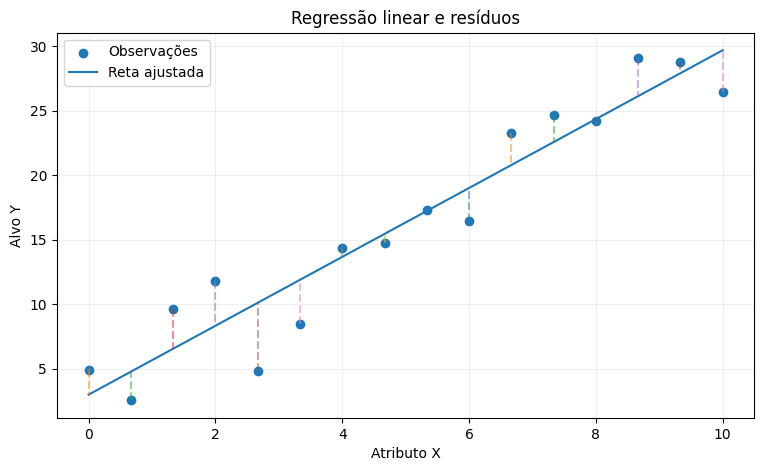

Inclinação estimada: 2.67
Intercepto estimado: 2.98


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Cria dados artificiais para demonstrar a regressão.
rng = np.random.default_rng(42)
x_demo = np.linspace(0, 10, 16)
y_demo = 4 + 2.5 * x_demo + rng.normal(0, 3, len(x_demo))

# Calcula a reta e suas previsões.
coef_demo = np.polyfit(x_demo, y_demo, deg=1)
y_prev_demo = np.polyval(coef_demo, x_demo)

# Mostra a reta, os pontos e os resíduos.
plt.figure(figsize=(9, 5))
plt.scatter(x_demo, y_demo, label="Observações")
plt.plot(x_demo, y_prev_demo, label="Reta ajustada")

for x, real, previsto in zip(x_demo, y_demo, y_prev_demo):
    plt.plot([x, x], [real, previsto], "--", alpha=0.5)

plt.xlabel("Atributo X")
plt.ylabel("Alvo Y")
plt.title("Regressão linear e resíduos")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Inclinação estimada: {coef_demo[0]:.2f}")
print(f"Intercepto estimado: {coef_demo[1]:.2f}")

### Resposta à pergunta do módulo:

Um erro de 10 unidades pesa mais que dois erros de 5 unidades porque o método dos mínimos quadrados eleva os erros ao quadrado. Assim, \(10^2=100\), enquanto \(5^2+5^2=50\).

# Módulo 2 — Conhecendo o dataset
### Etapa 2 — Carregamento do dataset Diabetes

Vamos carregar o conjunto de dados Diabetes e verificar a quantidade de amostras, atributos e os primeiros registros disponíveis.

In [2]:
import pandas as pd
import sklearn
from sklearn.datasets import load_diabetes

# Carrega o dataset Diabetes.
dados = load_diabetes(as_frame=True)

# Separa as características e o alvo.
X = dados.data.copy()
y = dados.target.copy()

# Apresenta as informações principais.
print("Versão do Scikit-learn:", sklearn.__version__)
print("Quantidade de amostras:", X.shape[0])
print("Quantidade de atributos:", X.shape[1])
print("Atributos:", list(X.columns))

display(X.head())

Versão do Scikit-learn: 1.6.1
Quantidade de amostras: 442
Quantidade de atributos: 10
Atributos: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


# Etapa 3 — Verificação dos dados
### Etapa 3 — Análise inicial dos dados

Nesta etapa, vamos observar as estatísticas do alvo e verificar se existem valores ausentes que possam prejudicar o treinamento.

---



In [3]:
# Mostra as estatísticas do valor que queremos prever.
print("Estatísticas do alvo:")
display(y.describe().to_frame("progressao"))

# Verifica valores ausentes nos atributos.
print("\nValores ausentes nos atributos:")
display(X.isna().sum().to_frame("ausentes"))

# Verifica valores ausentes no alvo.
print("Valores ausentes no alvo:", y.isna().sum())

Estatísticas do alvo:


,progressao
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000



Valores ausentes nos atributos:


,ausentes
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Valores ausentes no alvo: 0


**Interpretação**: O alvo deve ficar separado dos atributos de entrada. Utilizá-lo como característica causaria vazamento de dados e comprometeria a avaliação do modelo.

# Módulo 3 — Análise exploratória
### Etapa 4 — Distribuição dos valores

Vamos criar um histograma para entender como os valores da variável-alvo estão distribuídos no conjunto de dados.

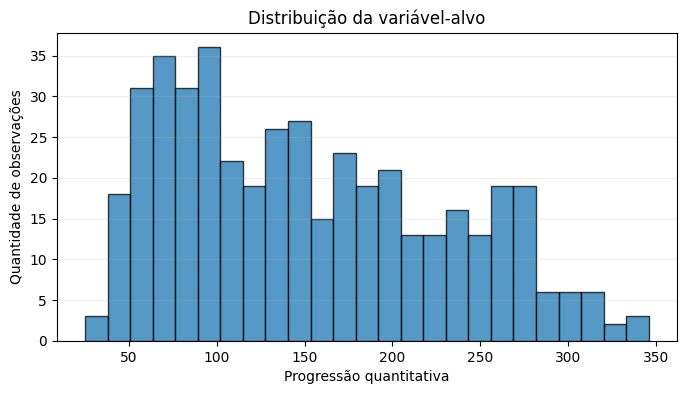

In [4]:
# Cria um histograma da variável-alvo.
plt.figure(figsize=(8, 4))
plt.hist(y, bins=25, edgecolor="black", alpha=0.75)

plt.xlabel("Progressão quantitativa")
plt.ylabel("Quantidade de observações")
plt.title("Distribuição da variável-alvo")
plt.grid(axis="y", alpha=0.2)
plt.show()

### Etapa 5 — Analisando o atributo BMI

Vamos verificar a relação entre o atributo `bmi` e a progressão da doença, utilizando um gráfico de dispersão e a correlação de Pearson.

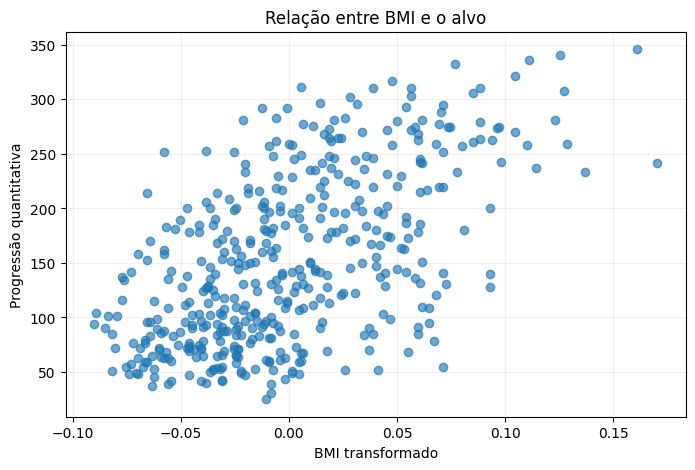

Correlação de Pearson: 0.586


In [5]:
# Mostra a relação entre BMI e o alvo.
plt.figure(figsize=(8, 5))
plt.scatter(X["bmi"], y, alpha=0.65)

plt.xlabel("BMI transformado")
plt.ylabel("Progressão quantitativa")
plt.title("Relação entre BMI e o alvo")
plt.grid(alpha=0.2)
plt.show()

# Calcula a correlação entre as variáveis.
correlacao = X["bmi"].corr(y)
print(f"Correlação de Pearson: {correlacao:.3f}")

### Etapa 6 — Correlação entre os atributos

Nesta etapa, vamos visualizar a correlação entre todas as características e o alvo, identificando possíveis relações entre as variáveis.

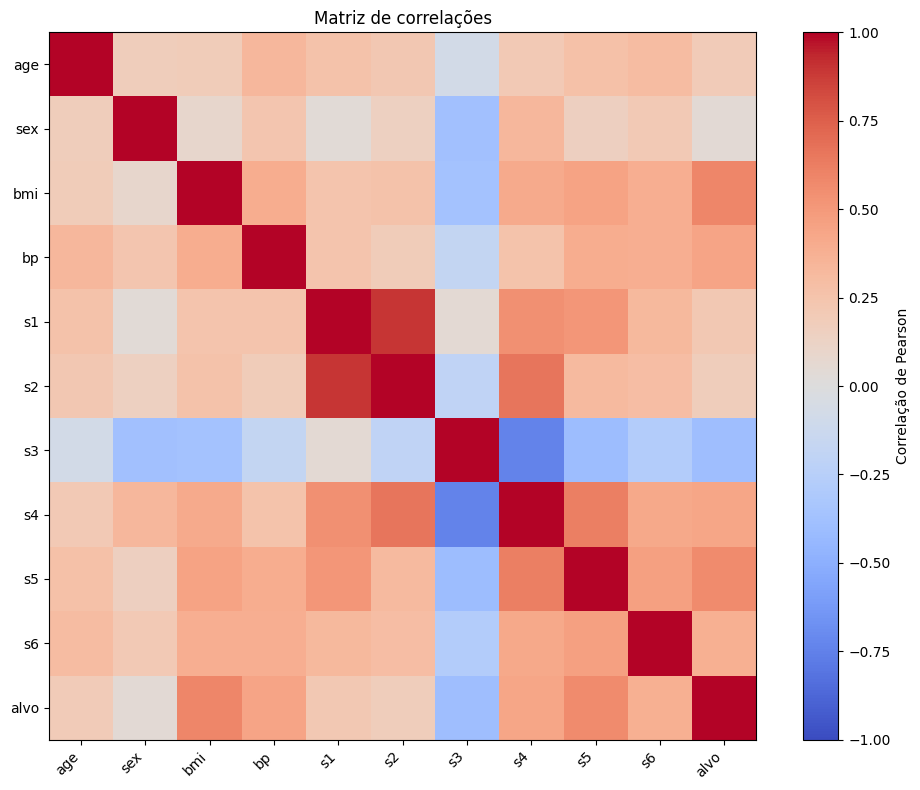

In [6]:
# Junta os atributos e o alvo para calcular as correlações.
base_exploratoria = X.copy()
base_exploratoria["alvo"] = y

correlacoes = base_exploratoria.corr()

# Cria o gráfico da matriz de correlação.
fig, ax = plt.subplots(figsize=(10, 8))
imagem = ax.imshow(correlacoes, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlacoes.columns)))
ax.set_xticklabels(correlacoes.columns, rotation=45, ha="right")

ax.set_yticks(range(len(correlacoes.index)))
ax.set_yticklabels(correlacoes.index)

fig.colorbar(imagem, ax=ax, label="Correlação de Pearson")
ax.set_title("Matriz de correlações")

plt.tight_layout()
plt.show()

**Interpretação:** Algumas características podem apresentar correlação entre si, indicando possível multicolinearidade. Uma correlação elevada não significa necessariamente que uma variável cause alterações na outra.

# Módulo 4 — Regressão linear simples
### Etapa 7 — Divisão entre treinamento e teste

Vamos utilizar apenas o atributo `bmi` para construir uma regressão simples. Os dados serão divididos em 80% para treinamento e 20% para teste.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Seleciona somente o atributo BMI.
X_simples = X[["bmi"]]

# Divide os dados em treino e teste.
X_treino_s, X_teste_s, y_treino_s, y_teste_s = train_test_split(
    X_simples,
    y,
    test_size=0.20,
    random_state=42
)

print("Treinamento:", X_treino_s.shape)
print("Teste:", X_teste_s.shape)

Treinamento: (353, 1)
Teste: (89, 1)


### Etapa 8 — Treinamento do modelo simples

Nesta etapa, vamos treinar uma regressão linear utilizando o BMI e observar o intercepto e o coeficiente encontrados pelo modelo.

In [8]:
# Cria e treina o modelo de regressão simples.
modelo_simples = LinearRegression()
modelo_simples.fit(X_treino_s, y_treino_s)

# Mostra os parâmetros aprendidos.
print(f"Intercepto: {modelo_simples.intercept_:.3f}")
print(f"Coeficiente do BMI: {modelo_simples.coef_[0]:.3f}")

Intercepto: 152.003
Coeficiente do BMI: 998.578


### Etapa 9 — Comparação entre valores reais e previstos

Vamos utilizar o modelo treinado para prever os valores do conjunto de teste e calcular os resíduos de cada previsão.

In [9]:
# Faz previsões com os dados de teste.
y_prev_s = modelo_simples.predict(X_teste_s)

# Organiza os valores reais, previstos e resíduos.
comparacao_simples = pd.DataFrame({
    "real": y_teste_s.to_numpy(),
    "previsto": y_prev_s,
    "residuo": y_teste_s.to_numpy() - y_prev_s
})

display(comparacao_simples.head(10))

,real,previsto,residuo
0,219.0,145.806227,73.193773
1,70.0,188.857390,-118.857390
2,202.0,147.958785,54.041215
3,230.0,203.925298,26.074702
4,111.0,131.814599,-20.814599
5,84.0,127.509482,-43.509482
6,242.0,322.315998,-80.315998
7,272.0,197.467623,74.532377
8,94.0,61.856458,32.143542
9,96.0,167.331809,-71.331809


### Etapa 10 — Visualização da reta de regressão

Vamos representar os dados de treinamento, os dados de teste e a reta aprendida para observar o comportamento do modelo.

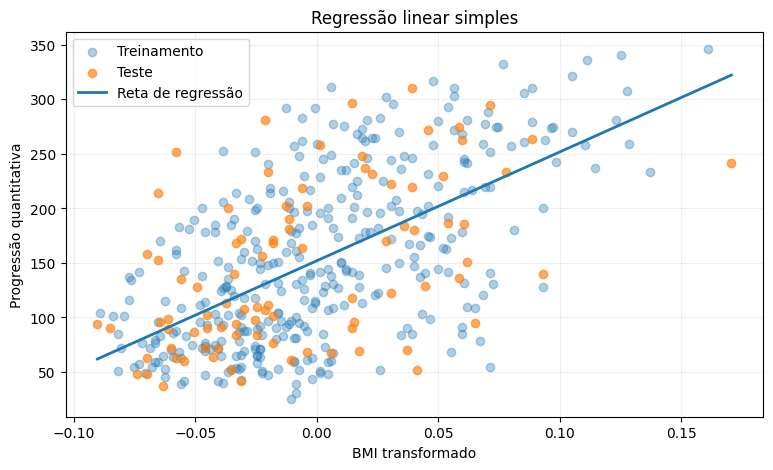

In [10]:
# Cria valores para desenhar a reta.
x_linha = pd.DataFrame({
    "bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 100)
})

y_linha = modelo_simples.predict(x_linha)

# Mostra os pontos e a reta ajustada.
plt.figure(figsize=(9, 5))

plt.scatter(
    X_treino_s["bmi"], y_treino_s,
    alpha=0.35, label="Treinamento"
)

plt.scatter(
    X_teste_s["bmi"], y_teste_s,
    alpha=0.65, label="Teste"
)

plt.plot(
    x_linha["bmi"], y_linha,
    linewidth=2, label="Reta de regressão"
)

plt.xlabel("BMI transformado")
plt.ylabel("Progressão quantitativa")
plt.title("Regressão linear simples")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Interpretação:** O coeficiente de bmi é positivo, indicando uma associação positiva com o alvo. A reta não passa por todos os pontos porque existem diferenças entre os valores reais e previstos. O intercepto representa a previsão quando o BMI transformado é zero, e não quando o BMI clínico é zero.

# Módulo 5 — Regressão linear múltipla
### Etapa 11 — Preparação da regressão múltipla

Agora vamos utilizar os 10 atributos do dataset para construir um modelo mais completo, mantendo 80% dos dados para treinamento e 20% para teste.

In [11]:
# Divide os dados utilizando todos os atributos.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

Treinamento: (353, 10)
Teste: (89, 10)


### Etapa 12 — Treinamento do modelo múltiplo

Vamos treinar uma regressão linear utilizando todas as características disponíveis e realizar previsões para os dados de teste.

In [12]:
# Cria e treina o modelo com os dez atributos.
modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_treino, y_treino)

# Faz previsões para os dados de teste.
y_prev_m = modelo_multiplo.predict(X_teste)

print(f"Intercepto: {modelo_multiplo.intercept_:.2f}")
print("Treinamento concluído com sucesso!")

Intercepto: 151.35
Treinamento concluído com sucesso!


### Etapa 13 — Coeficientes da regressão múltipla

Nesta etapa, vamos visualizar os coeficientes aprendidos pelo modelo e observar quais apresentam valores positivos ou negativos.

,coeficiente
s1,-931.488846
sex,-241.964362
age,37.904021
s6,48.670657
s3,163.419983
s4,275.317902
bp,347.703844
s2,518.062277
bmi,542.428759
s5,736.198859


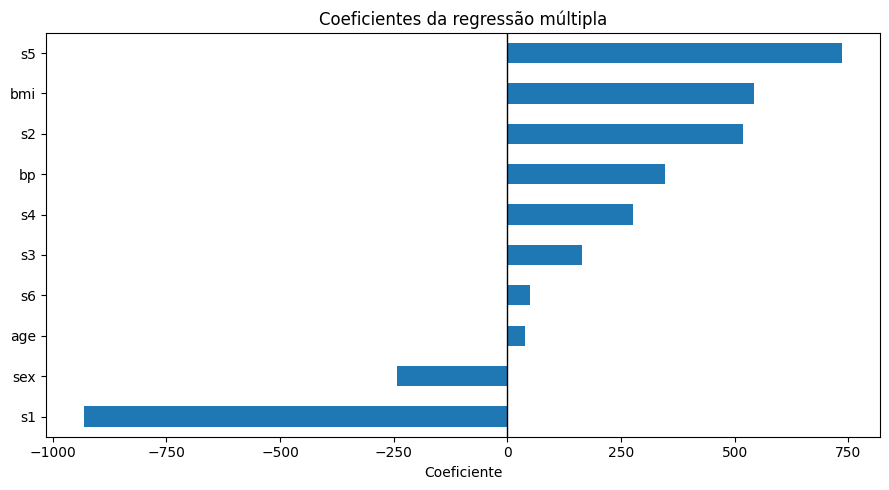

In [13]:
# Organiza os coeficientes de cada atributo.
coeficientes = pd.Series(
    modelo_multiplo.coef_,
    index=X.columns,
    name="coeficiente"
)

display(coeficientes.sort_values().to_frame())

# Cria um gráfico com os coeficientes.
coeficientes.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Coeficiente")
plt.title("Coeficientes da regressão múltipla")
plt.tight_layout()
plt.show()

**Interpretação:** Os coeficientes indicam a associação de cada atributo com o valor previsto, mantendo os demais constantes. Entretanto, valores maiores não significam necessariamente maior importância causal.

# Módulo 6 — Métricas e análise de resíduos
### Etapa 14 — Avaliação com MAE, MSE, RMSE e R²

Vamos calcular as principais métricas de regressão e comparar os resultados do modelo simples, do modelo múltiplo e de um modelo básico que prevê a média dos valores de treinamento.

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

# Função para calcular as métricas dos modelos.
def avaliar(nome, observado, previsto):
    mse = mean_squared_error(observado, previsto)

    return {
        "modelo": nome,
        "MAE": mean_absolute_error(observado, previsto),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(observado, previsto)
    }

# Cria um modelo básico que prevê a média.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_treino, y_treino)
y_prev_base = baseline.predict(X_teste)

# Compara os três modelos.
resultados = [
    avaliar("Baseline (média)", y_teste, y_prev_base),
    avaliar("Linear simples (bmi)", y_teste_s, y_prev_s),
    avaliar("Linear múltipla", y_teste, y_prev_m)
]

display(pd.DataFrame(resultados).round(3))

,modelo,MAE,MSE,RMSE,R2
0,Baseline (média),64.006,5361.533,73.222,-0.012
1,Linear simples (bmi),52.260,4061.826,63.732,0.233
2,Linear múltipla,42.794,2900.194,53.853,0.453


### Etapa 15 — Comparação entre valores reais e previstos

Vamos criar um gráfico para observar o quanto as previsões da regressão múltipla se aproximam dos valores reais.

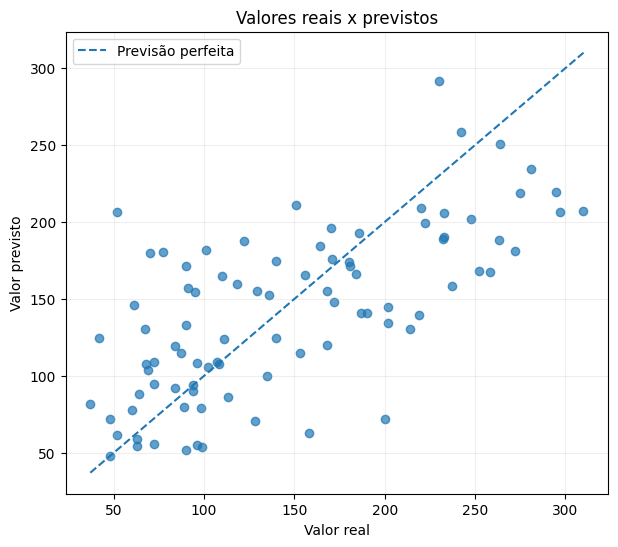

In [15]:
# Mostra os valores reais e previstos.
plt.figure(figsize=(7, 6))
plt.scatter(y_teste, y_prev_m, alpha=0.7)

# Desenha a linha que representa previsões perfeitas.
limites = [
    min(y_teste.min(), y_prev_m.min()),
    max(y_teste.max(), y_prev_m.max())
]

plt.plot(limites, limites, "--", label="Previsão perfeita")

plt.xlabel("Valor real")
plt.ylabel("Valor previsto")
plt.title("Valores reais x previstos")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Etapa 16 — Análise dos erros do modelo

Nesta etapa, vamos analisar os resíduos da regressão múltipla para identificar erros elevados, possíveis padrões e limitações das previsões.

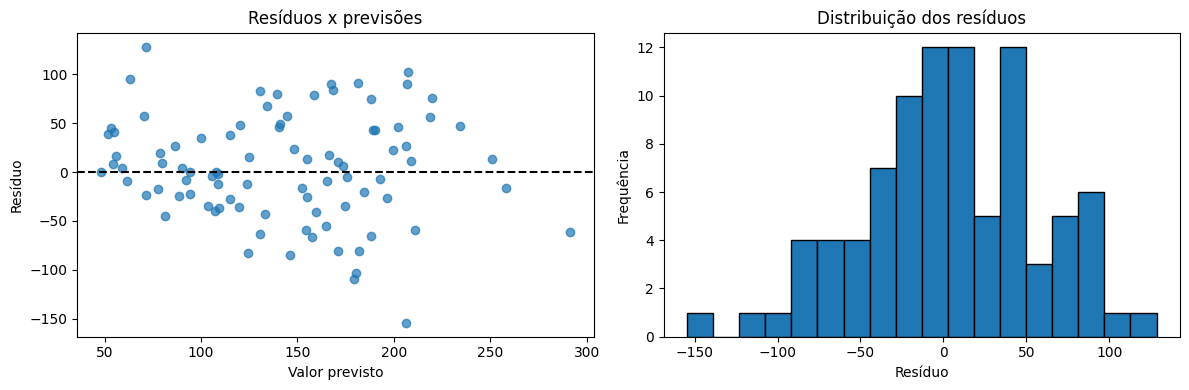

In [16]:
# Calcula a diferença entre valores reais e previstos.
residuos = y_teste.to_numpy() - y_prev_m

# Cria dois gráficos para analisar os resíduos.
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

eixos[0].scatter(y_prev_m, residuos, alpha=0.7)
eixos[0].axhline(0, linestyle="--", color="black")
eixos[0].set_xlabel("Valor previsto")
eixos[0].set_ylabel("Resíduo")
eixos[0].set_title("Resíduos x previsões")

eixos[1].hist(residuos, bins=18, edgecolor="black")
eixos[1].set_xlabel("Resíduo")
eixos[1].set_ylabel("Frequência")
eixos[1].set_title("Distribuição dos resíduos")

plt.tight_layout()
plt.show()

**Interpretação:** Os resíduos mostram que o modelo não consegue prever todos os valores com precisão. Erros extremos e possíveis padrões indicam limitações que precisam ser consideradas na análise.

# Módulo 7 — Generalização e validação cruzada
### Etapa 17 — Avaliação com validação cruzada

Vamos utilizar a validação cruzada com cinco divisões para avaliar o desempenho da regressão múltipla em diferentes partes do conjunto de treinamento.

In [17]:
from sklearn.model_selection import KFold, cross_validate

# Configura a validação cruzada com cinco divisões.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Define as métricas utilizadas.
metricas_cv = {
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

# Avalia o modelo somente com os dados de treinamento.
cv_resultado = cross_validate(
    LinearRegression(),
    X_treino,
    y_treino,
    cv=cv,
    scoring=metricas_cv
)

# Organiza os resultados.
maes = -cv_resultado["test_mae"]
r2s = cv_resultado["test_r2"]

print("MAE por divisão:", np.round(maes, 2))
print(f"MAE médio: {maes.mean():.2f} ± {maes.std():.2f}")
print(f"R² médio: {r2s.mean():.3f} ± {r2s.std():.3f}")

MAE por divisão: [44.59 48.28 42.93 44.3  45.15]
MAE médio: 45.05 ± 1.77
R² médio: 0.480 ± 0.041


### Etapa 18 — Verificando a generalização

Vamos comparar o desempenho da regressão múltipla nos conjuntos de treinamento e teste para observar possíveis sinais de overfitting ou underfitting.

In [18]:
# Faz previsões nos dados de treinamento.
prev_treino = modelo_multiplo.predict(X_treino)

# Compara as métricas de treino e teste.
quadro = pd.DataFrame([
    avaliar("Treino", y_treino, prev_treino),
    avaliar("Teste", y_teste, y_prev_m)
])

display(quadro[["modelo", "MAE", "RMSE", "R2"]].round(3))

,modelo,MAE,RMSE,R2
0,Treino,43.484,53.559,0.528
1,Teste,42.794,53.853,0.453


**Interpretação:** Se um modelo apresenta desempenho muito melhor no treinamento do que no teste, isso pode indicar overfitting. Por isso, os hiperparâmetros devem ser escolhidos por validação cruzada, sem utilizar repetidamente os resultados do teste.

# Módulo 8 — Regularização e não linearidade
### Etapa 19 — Comparando modelos de regressão

Vamos comparar regressão linear, Ridge e Lasso utilizando validação cruzada. A padronização será realizada dentro de um Pipeline para evitar vazamento de dados.

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso

# Define os modelos que serão comparados.
candidatos = {
    "Linear": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge alpha=1": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso alpha=1": make_pipeline(
        StandardScaler(),
        Lasso(alpha=1.0, max_iter=20000)
    )
}

linhas = []

# Avalia cada modelo por validação cruzada.
for nome, estimador in candidatos.items():
    resultado = cross_validate(
        estimador,
        X_treino,
        y_treino,
        cv=cv,
        scoring=metricas_cv
    )

    linhas.append({
        "modelo": nome,
        "MAE_CV": -resultado["test_mae"].mean(),
        "R2_CV": resultado["test_r2"].mean()
    })

# Mostra os resultados ordenados pelo menor erro.
tabela_cv = pd.DataFrame(linhas).sort_values("MAE_CV")
display(tabela_cv.round(3))

,modelo,MAE_CV,R2_CV
1,Ridge alpha=1,44.999,0.481
0,Linear,45.048,0.480
2,Lasso alpha=1,45.136,0.481


### Etapa 20 — Comparando regressão linear e polinomial

Nesta etapa, vamos testar uma regressão polinomial de grau 2 utilizando o BMI e comparar seu desempenho com o modelo linear simples.

,modelo,MAE,MSE,RMSE,R2
0,Linear simples,52.260,4061.826,63.732,0.233
1,Polinomial grau 2,52.384,4085.025,63.914,0.229


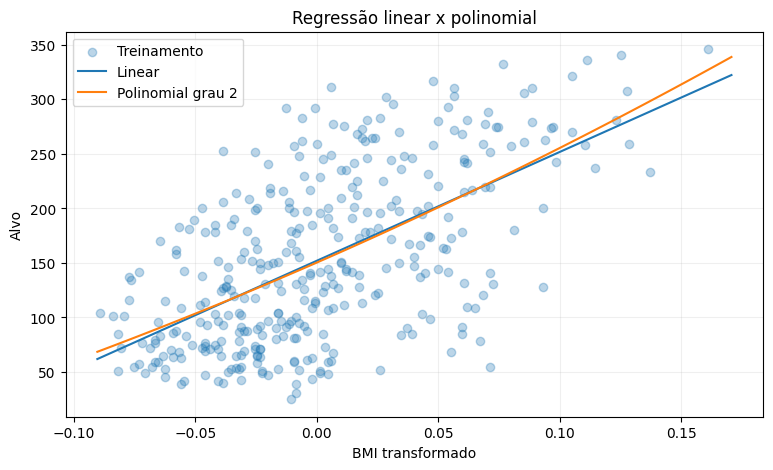

In [20]:
from sklearn.preprocessing import PolynomialFeatures

# Cria um modelo polinomial de grau 2.
modelo_polinomial = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Treina o modelo com os dados de treinamento.
modelo_polinomial.fit(X_treino_s, y_treino_s)

# Faz previsões e compara as métricas.
prev_poli = modelo_polinomial.predict(X_teste_s)

display(pd.DataFrame([
    avaliar("Linear simples", y_teste_s, y_prev_s),
    avaliar("Polinomial grau 2", y_teste_s, prev_poli)
]).round(3))

# Compara a reta e a curva.
plt.figure(figsize=(9, 5))

plt.scatter(
    X_treino_s["bmi"], y_treino_s,
    alpha=0.3, label="Treinamento"
)

plt.plot(
    x_linha["bmi"],
    modelo_simples.predict(x_linha),
    label="Linear"
)

plt.plot(
    x_linha["bmi"],
    modelo_polinomial.predict(x_linha),
    label="Polinomial grau 2"
)

plt.xlabel("BMI transformado")
plt.ylabel("Alvo")
plt.title("Regressão linear x polinomial")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Etapa 21 — Ajuste de hiperparâmetros com GridSearchCV

Vamos testar diferentes valores de `alpha` no Ridge utilizando apenas os dados de treinamento. O objetivo é encontrar o valor que apresenta menor erro médio na validação cruzada.

In [21]:
from sklearn.model_selection import GridSearchCV

# Cria o Pipeline do Ridge.
pipeline_ridge = make_pipeline(
    StandardScaler(),
    Ridge()
)

# Configura a busca por diferentes valores de alpha.
busca = GridSearchCV(
    pipeline_ridge,
    param_grid={
        "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

# Realiza a busca somente com os dados de treinamento.
busca.fit(X_treino, y_treino)

print("Melhor alpha:", busca.best_params_["ridge__alpha"])
print(f"MAE médio de validação: {-busca.best_score_:.2f}")

Melhor alpha: 1
MAE médio de validação: 45.00


### Etapa 22 — Avaliação do Ridge ajustado

Vamos avaliar o Ridge com o melhor `alpha` encontrado e comparar suas métricas com o modelo básico e a regressão linear múltipla.

In [22]:
# Faz previsões utilizando o melhor Ridge.
prev_ridge = busca.predict(X_teste)

# Compara os resultados finais.
comparacao_final = pd.DataFrame([
    avaliar("Baseline", y_teste, y_prev_base),
    avaliar("Linear múltipla", y_teste, y_prev_m),
    avaliar("Ridge ajustado por CV", y_teste, prev_ridge)
])

display(comparacao_final.round(3))

,modelo,MAE,MSE,RMSE,R2
0,Baseline,64.006,5361.533,73.222,-0.012
1,Linear múltipla,42.794,2900.194,53.853,0.453
2,Ridge ajustado por CV,42.812,2892.015,53.777,0.454


# Módulo 9 — Exercício final

### Questão 1 — Fundamentos

A regressão é utilizada para prever valores numéricos, como a progressão de uma doença. A classificação identifica categorias, como um exame positivo ou negativo. Já o clustering agrupa dados semelhantes sem utilizar classes previamente definidas, podendo ajudar a identificar grupos de pacientes com características parecidas.

### Questão 2 — Intercepto e coeficiente do BMI

O intercepto representa o valor previsto quando o BMI transformado é igual a zero. O coeficiente de BMI indica quanto a previsão varia quando esse atributo aumenta uma unidade. Como o coeficiente é positivo, existe uma associação positiva entre BMI e o alvo. Entretanto, essa relação não comprova causalidade, pois outros fatores podem influenciar os resultados.

### Questão 3 — Métricas de avaliação

O MAE representa a média dos erros absolutos das previsões. O RMSE também mede os erros, mas penaliza mais fortemente os erros grandes, pois utiliza o quadrado das diferenças. O R² indica o desempenho do modelo em relação à previsão pela média dos valores observados. Um R² negativo é possível e significa que o modelo apresentou desempenho pior do que essa referência.

### Questão 4 — Análise do atributo BP

Vamos analisar o atributo `bp`, diferente de `bmi`, para observar sua relação com a variável-alvo. Utilizaremos um gráfico de dispersão e a correlação de Pearson.


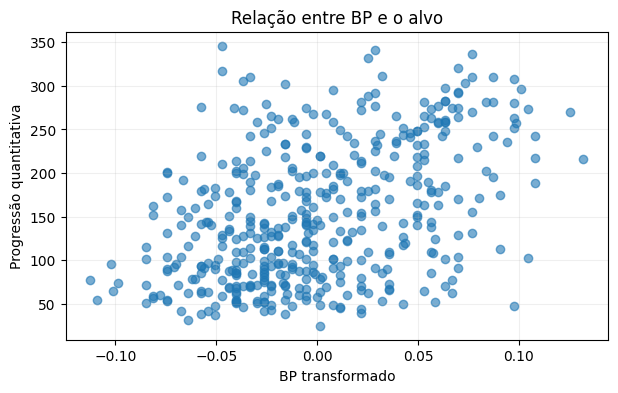

Correlação de Pearson: 0.441


In [23]:
# Escolhe um atributo diferente de BMI.
atributo_escolhido = "bp"

# Cria o gráfico de dispersão.
plt.figure(figsize=(7, 4))
plt.scatter(X[atributo_escolhido], y, alpha=0.6)

plt.xlabel("BP transformado")
plt.ylabel("Progressão quantitativa")
plt.title("Relação entre BP e o alvo")
plt.grid(alpha=0.2)
plt.show()

# Calcula a correlação entre BP e o alvo.
print(
    "Correlação de Pearson:",
    round(X[atributo_escolhido].corr(y), 3)
)

**Interpretação:** O gráfico apresenta uma tendência positiva entre o atributo `bp` e a progressão da doença. Entretanto, os pontos estão relativamente dispersos, indicando que o atributo sozinho não explica toda a variação do alvo. A correlação mostra uma associação, mas não comprova uma relação de causa e efeito.

### Questão 5 — Comparação entre BMI e BP

Vamos treinar uma regressão linear simples utilizando `bp` e comparar seu desempenho com o modelo anterior, que utilizou `bmi`, considerando MAE e R².

In [24]:
# Seleciona o atributo BP.
X_alternativo = X[[atributo_escolhido]]

# Mantém a mesma divisão de treino e teste.
Xa_treino, Xa_teste, ya_treino, ya_teste = train_test_split(
    X_alternativo,
    y,
    test_size=0.20,
    random_state=42
)

# Treina o modelo alternativo.
modelo_alternativo = LinearRegression()
modelo_alternativo.fit(Xa_treino, ya_treino)

# Realiza as previsões.
prev_alternativa = modelo_alternativo.predict(Xa_teste)

# Compara os dois modelos.
comparacao_q5 = pd.DataFrame([
    avaliar("BMI", y_teste_s, y_prev_s),
    avaliar("BP", ya_teste, prev_alternativa)
])

display(comparacao_q5.round(3))

,modelo,MAE,MSE,RMSE,R2
0,BMI,52.260,4061.826,63.732,0.233
1,BP,57.224,4379.390,66.177,0.173


**Interpretação:** O modelo utilizando `bmi` apresentou melhor desempenho, com MAE de aproximadamente **52,26** e R² de **0,233**. Já o modelo com `bp` obteve MAE de aproximadamente **57,22** e R² de **0,173**. Portanto, o BMI generalizou melhor nesta divisão, pois apresentou menor erro e maior capacidade de explicar a variação dos dados.

### Questão 6 — Comparação dos valores de Alpha no Ridge

Vamos comparar quatro valores de `alpha` utilizando validação cruzada com cinco divisões. Também analisaremos a variação dos erros para verificar a estabilidade dos resultados.

In [25]:
# Lista para armazenar os resultados.
resultados_alpha = []

# Testa os quatro valores solicitados.
for alpha in [0.1, 1, 10, 100]:

    # Cria o modelo Ridge com padronização.
    modelo = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    # Executa a validação cruzada no treino.
    notas = cross_validate(
        modelo,
        X_treino,
        y_treino,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    # Guarda a média e o desvio dos erros.
    erros = -notas["test_score"]

    resultados_alpha.append({
        "alpha": alpha,
        "MAE_CV": erros.mean(),
        "desvio_CV": erros.std()
    })

# Organiza e apresenta os resultados.
tabela_alpha = pd.DataFrame(resultados_alpha)
display(tabela_alpha.round(3))

# Identifica o menor erro médio.
melhor = tabela_alpha.loc[tabela_alpha["MAE_CV"].idxmin()]

print("Melhor alpha:", melhor["alpha"])
print(f"Menor MAE médio: {melhor['MAE_CV']:.3f}")

,alpha,MAE_CV,desvio_CV
0,0.1,45.041,1.777
1,1.0,44.999,1.808
2,10.0,45.060,1.951
3,100.0,46.047,2.869


Melhor alpha: 1.0
Menor MAE médio: 44.999


**Interpretação:** O valor de `alpha=1` apresentou o menor MAE médio na validação cruzada entre os quatro valores testados. Os resultados dos valores menores foram próximos, indicando que pequenas mudanças na regularização não alteraram muito o desempenho. Entretanto, valores maiores podem aumentar o erro por restringirem excessivamente os coeficientes. A estabilidade deve ser analisada considerando também o desvio dos erros entre as divisões.

### Questão 7 — Análise dos resíduos

O gráfico de resíduos da regressão múltipla apresenta valores positivos e negativos, sem uma relação perfeitamente uniforme. Também existem erros de maior magnitude, mostrando que algumas previsões ficaram distantes dos valores reais. Isso indica que o modelo possui limitações e pode não representar completamente todas as relações existentes nos dados.

### Questão 8 — Viés na escolha dos modelos

Escolher repetidamente o modelo com melhor resultado no conjunto de teste pode causar viés, porque acabamos adaptando nossas decisões aos próprios dados usados para avaliação. A validação cruzada permite comparar modelos e ajustar hiperparâmetros utilizando apenas o treinamento. Dessa forma, o conjunto de teste permanece reservado para uma avaliação final mais confiável.

### Questão 9 — Relatório Final: Regressão com Scikit-learn

O objetivo desta atividade foi compreender o funcionamento dos modelos de regressão supervisionada e avaliar sua capacidade de prever valores numéricos. Para isso, utilizamos o dataset Diabetes, disponível na biblioteca Scikit-learn, composto por 442 observações e 10 atributos numéricos. Os dados foram divididos em 80% para treinamento e 20% para teste, utilizando `random_state=42` para garantir a reprodução dos resultados. Durante os experimentos, analisamos os atributos, suas correlações e a relação entre os valores reais e previstos.

Foram desenvolvidos e comparados diferentes modelos, incluindo regressão linear simples, regressão linear múltipla, regressão polinomial, Ridge e Lasso. Também utilizamos um modelo básico que prevê a média dos valores de treinamento. Para avaliar o desempenho, consideramos as métricas MAE, MSE, RMSE e R², além da validação cruzada. A regressão simples utilizando BMI apresentou MAE de aproximadamente 52,26 e R² de 0,233, superando o modelo simples com BP. A regressão múltipla apresentou resultados melhores, com MAE de aproximadamente 42,79 e R² de 0,453. O Ridge ajustado também apresentou desempenho semelhante, com MAE próximo de 42,81 e R² de 0,454.

Os resultados mostram que utilizar diferentes atributos pode melhorar a capacidade preditiva do modelo. Entretanto, também observamos limitações, como resíduos elevados, possíveis relações não lineares e diferenças entre treinamento e teste. A validação cruzada ajudou a avaliar a estabilidade dos modelos e a escolher hiperparâmetros sem depender diretamente do conjunto de teste. Concluímos que os modelos de regressão são úteis para identificar padrões e realizar previsões, mas seus resultados precisam ser interpretados com cuidado. Por se tratar de uma atividade didática, os modelos desenvolvidos não estão prontos para utilização clínica.